# EDA 08 · Integration, redundancy and drift

**Question.** What is the final feature set, does every block earn its place, how does it compare with the current w1 features, and is it stable between the February development cohort and the March test cohort?

**Input.** The blocks kept by notebooks 01–06 (all built by `_common.py` with the cleaning rules of notebooks 02 and 05), plus the candidates left **open**:

| Open candidate | From |
|---|---|
| `dsl_band` (days since last transaction) | notebook 03 |
| `expire_dow` (weekday of the current expiry, current w1) | notebook 03 |
| `n_free`, `n_methods`, `auto_share` | notebook 04 |
| `city_group` | notebook 01 |

**Population.** `fit` for every model. The March cohort is used **without labels**, only to compare feature distributions (section 6).

In [1]:
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

pl.Config.set_tbl_rows(60); pl.Config.set_tbl_width_chars(160)
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.max_colwidth", None)
FEB_CUTOFF, MAR_CUTOFF = date(2017, 1, 31), date(2017, 2, 28)

## 1. Building the final candidate table

In [2]:
def build_features(users, keep_methods=None, keep_cities=None):
    txn = C.clean_transactions(users)
    st = C.state_block(C.subscription_state(txn, users), keep_methods=keep_methods)
    extra = (txn.filter(pl.col("is_cancel") == 0).group_by("msno").agg(
        n_free=(pl.col("price_type") == "free").sum(), n_methods=pl.col("payment_method_id").n_unique(),
        auto_share=pl.col("is_auto_renew").mean()))
    city = C.scan_members(users).select("msno", "city").collect()
    df = (st.join(C.history_block(txn, users), on="msno")
            .join(C.listening_block(users), on="msno")
            .join(C.member_block(users), on="msno")
            .join(extra, on="msno", how="left")
            .join(city, on="msno", how="left"))
    df = df.with_columns(
        pl.col("n_free", "n_methods").fill_null(0),
        expire_dow=pl.col("last_expire").dt.weekday().cast(pl.String).fill_null("none"),
        city_raw=pl.when(pl.col("city").is_null()).then(pl.lit("no member"))
        .when((pl.col("city") == 1) & (pl.col("profile_state") == "incomplete")).then(pl.lit("unknown"))
        .otherwise(pl.col("city").cast(pl.String)))
    if keep_cities is None:
        cnt = df.group_by("city_raw").len()
        keep_cities = cnt.filter(pl.col("len") >= 1000)["city_raw"].to_list()
    df = df.with_columns(city_group=pl.when(pl.col("city_raw").is_in(keep_cities)).then(pl.col("city_raw"))
                         .otherwise(pl.lit("other")))
    return df, keep_cities

C.set_cutoff(FEB_CUTOFF)
users = C.load_fit_population()
BASE = users["is_churn"].mean()
fit, KEEP_CITIES = build_features(users)
KEEP_METHODS = [int(m) for m in fit["pm_group"].unique().to_list() if m not in ("other", "none")]
print(f"fit customers: {fit.height:,} | payment methods kept: {len(KEEP_METHODS)} | cities kept: {len(KEEP_CITIES)}")

fit customers: 744,699 | payment methods kept: 16 | cities kept: 20


In [3]:
STATE_CAT = [c for c in C.STATE_BLOCK if c != "dsl_band"]
BLOCKS = {
    "state (cat)": STATE_CAT,
    "history (num)": C.HISTORY_BLOCK,
    "listening (num)": C.LISTEN_BLOCK,
    "members (cat + num)": C.MEMBER_CAT + C.MEMBER_NUM,
}
OPEN = {"dsl_band": "cat", "expire_dow": "cat", "city_group": "cat", "n_free": "num", "n_methods": "num", "auto_share": "num"}
CAT_ALL = set(STATE_CAT + C.MEMBER_CAT + ["dsl_band", "expire_dow", "city_group"])
pd.DataFrame([{"block": b, "features": ", ".join(cols), "n": len(cols)} for b, cols in BLOCKS.items()]
             + [{"block": "open candidates", "features": ", ".join(OPEN), "n": len(OPEN)}])

,block,features,n
0,state (cat),"state, expiry_state, plan_band, price_level, price_type, pm_group",6
1,history (num),"payer_days, n_payments, n_lapses, total_lapse_days",4
2,listening (num),"has_logs, days_since_last_log, longest_gap, active_days_30, secs_30",5
3,members (cat + num),"via, profile_state, age_band, bd, tenure_days",5
4,open candidates,"dsl_band, expire_dow, city_group, n_free, n_methods, auto_share",6


## 2. Does every block earn its place? (gradient boosting, 5-fold CV inside fit)

Full set = the four blocks. Each block is removed in turn, then each open candidate is added in turn.

In [4]:
data = fit.to_pandas()
y = fit["is_churn"].to_numpy()
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=C.SEED)

def gbm_cv(cols):
    cat = [c for c in cols if c in CAT_ALL]; num = [c for c in cols if c not in CAT_ALL]
    pre = ColumnTransformer([("num", "passthrough", num),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    model = make_pipeline(pre, HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=C.SEED))
    s = cross_validate(model, data[num + cat], y, cv=CV, scoring=("roc_auc", "average_precision", "neg_log_loss"), n_jobs=5)
    return {"roc_auc": s["test_roc_auc"].mean(), "avg_precision": s["test_average_precision"].mean(),
            "log_loss": -s["test_neg_log_loss"].mean(), "n_features": len(cols)}

FULL = [c for cols in BLOCKS.values() for c in cols]
runs = {"full (4 blocks)": FULL}
for b, cols in BLOCKS.items():
    runs[f"- {b}"] = [c for c in FULL if c not in cols]
for c in OPEN:
    runs[f"+ {c}"] = FULL + [c]
abl = pd.DataFrame({k: gbm_cv(v) for k, v in runs.items()}).T
abl["d_auc"] = abl["roc_auc"] - abl.loc["full (4 blocks)", "roc_auc"]
abl["d_ap"] = abl["avg_precision"] - abl.loc["full (4 blocks)", "avg_precision"]
abl

,roc_auc,avg_precision,log_loss,n_features,d_auc,d_ap
full (4 blocks),0.9001,0.5967,0.1421,20.0000,0.0000,0.0000
- state (cat),0.8497,0.3958,0.1765,14.0000,-0.0504,-0.2009
- history (num),0.8905,0.5849,0.1451,16.0000,-0.0096,-0.0118
- listening (num),0.8943,0.5723,0.1459,15.0000,-0.0058,-0.0244
- members (cat + num),0.8996,0.5953,0.1424,15.0000,-0.0005,-0.0014
+ dsl_band,0.9002,0.5973,0.1420,21.0000,0.0001,0.0005
+ expire_dow,0.9001,0.5965,0.1422,21.0000,0.0000,-0.0002
+ city_group,0.9000,0.5966,0.1422,21.0000,-0.0001,-0.0001
+ n_free,0.9002,0.5965,0.1421,21.0000,0.0001,-0.0002
+ n_methods,0.9001,0.5965,0.1422,21.0000,0.0000,-0.0003



- **State is the backbone**: without it AP falls from 0.597 to 0.396 (−0.20).
- **Listening** (−0.024 AP) and **history** (−0.012 AP) each carry a real share once the others are present.
- **Members** add little to a tree model (−0.0014 AP, −0.0005 AUC when removed). They stay because they are cheap, stable (section 6) and worth more to the linear model, which cannot find channel and tenure effects through other variables.
- **None of the open candidates** moves AUC or AP by more than 0.0005: `dsl_band`, `expire_dow`, `city_group`, `n_free`, `n_methods` and `auto_share` are all dropped.


## 3. The same information for a linear model

The logistic regression only sees what the encoding gives it. Numeric features are cut into the bands used in notebooks 01–06, and the interactions those notebooks found are added explicitly: `state × expiry_state`, `via × profile_state`, and the history and recency bands crossed with "manual payment".

In [5]:
def bands(col, edges):
    e = pl.when(pl.col(col).is_null()).then(pl.lit("none"))
    lo = None
    for x in edges:
        e = e.when(pl.col(col) <= x).then(pl.lit(f"<= {x:g}" if lo is None else f"({lo:g}, {x:g}]")); lo = x
    return e.otherwise(pl.lit(f"> {edges[-1]:g}"))

BANDS = {"payer_days": [90, 180, 365, 545, 730], "n_payments": [3, 8, 15, 22], "n_lapses": [0, 1, 3, 6],
         "total_lapse_days": [0, 30, 90, 365], "days_since_last_log": [0, 3, 7, 14, 30, 89],
         "longest_gap": [3, 7, 14, 30, 60], "active_days_30": [0, 5, 15, 25], "secs_30": [0, 1e3, 1e4, 5e4, 1.5e5],
         "tenure_days": [30, 182, 365, 730, 1461, 2922]}
lin = fit.with_columns([bands(c, e).alias(f"{c}_b") for c, e in BANDS.items()])
manual = pl.when(pl.col("state") == "manual").then(pl.lit("manual")).otherwise(pl.lit("other"))
lin = lin.with_columns(
    state_x_expiry=pl.col("state") + "|" + pl.col("expiry_state"),
    via_x_profile=pl.col("via") + "|" + pl.col("profile_state"),
    *[(manual + "|" + pl.col(f"{c}_b")).alias(f"{c}_x_manual")
      for c in ("payer_days", "n_payments", "n_lapses", "days_since_last_log", "active_days_30")])
BASE_LIN = STATE_CAT + ["via", "profile_state", "age_band"] + [f"{c}_b" for c in BANDS]
INTER = ["state_x_expiry", "via_x_profile"] + [f"{c}_x_manual" for c in ("payer_days", "n_payments", "n_lapses", "days_since_last_log", "active_days_30")]
ldata = lin.to_pandas()

def lr_cv(cols):
    model = make_pipeline(ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), cols)]),
                          LogisticRegression(max_iter=4000, C=1.0))
    s = cross_validate(model, ldata[cols], y, cv=CV, scoring=("roc_auc", "average_precision", "neg_log_loss"), n_jobs=5)
    return {"roc_auc": s["test_roc_auc"].mean(), "avg_precision": s["test_average_precision"].mean(),
            "log_loss": -s["test_neg_log_loss"].mean(), "n_columns": len(cols)}

lr_res = pd.DataFrame({"logistic, bands only": lr_cv(BASE_LIN), "logistic, bands + interactions": lr_cv(BASE_LIN + INTER)}).T
lr_res

,roc_auc,avg_precision,log_loss,n_columns
"logistic, bands only",0.8794,0.5563,0.1504,18.0000
"logistic, bands + interactions",0.8832,0.5682,0.1484,25.0000



With bands only, the logistic regression reaches AUC 0.879 / AP 0.556. Adding the seven interactions found in notebooks 01–06 raises it to **0.883 / 0.568** (+0.012 AP), confirming that those interactions are real. The linear model stays below gradient boosting (0.900 / 0.597), so in w1 it is the interpretable baseline, built with these bands and interactions, not the reference model.


## 4. Against the current w1 features

The w1 export (`w1/export-tabular-v5/train_feb.parquet`, 59 features built by the current pipeline) restricted to the same `fit` customers and evaluated with the same gradient boosting and folds.

In [6]:
w1 = pl.read_parquet(C.WORKSHOPS_DIR / "w1" / "export-tabular-v5" / "train_feb.parquet")
w1 = users.select("msno").join(w1, on="msno", how="left")
assert w1.height == fit.height and (w1["msno"] == fit["msno"]).all()
W1_FEATS = [c for c in w1.columns if c not in ("msno", "is_churn")]
w1d = w1.select(W1_FEATS).to_pandas().astype(float)
model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=C.SEED)
s = cross_validate(model, w1d, y, cv=CV, scoring=("roc_auc", "average_precision", "neg_log_loss"), n_jobs=5)
cmp = pd.DataFrame({
    f"current w1 features ({len(W1_FEATS)})": {"roc_auc": s["test_roc_auc"].mean(), "avg_precision": s["test_average_precision"].mean(),
                                               "log_loss": -s["test_neg_log_loss"].mean(), "n_features": len(W1_FEATS)},
    f"proposed ({len(FULL)})": abl.loc["full (4 blocks)", ["roc_auc", "avg_precision", "log_loss", "n_features"]].to_dict(),
}).T
cmp

,roc_auc,avg_precision,log_loss,n_features
current w1 features (108),0.8976,0.5879,0.1437,108.0000
proposed (20),0.9001,0.5967,0.1421,20.0000



With the same model and folds, the **20 proposed features beat the 108 columns of the current w1 export**: AUC 0.9001 vs 0.8976, AP 0.597 vs 0.588, log-loss 0.1421 vs 0.1437. The proposed set is smaller, each feature is justified by a notebook, and the known defects are gone: 2015 zeros, cumulative `duration`, constant flags, file-order state, mean-imputed age, p99.9 clipping and active-month listening blocks.


## 5. Redundancy in the final numeric set

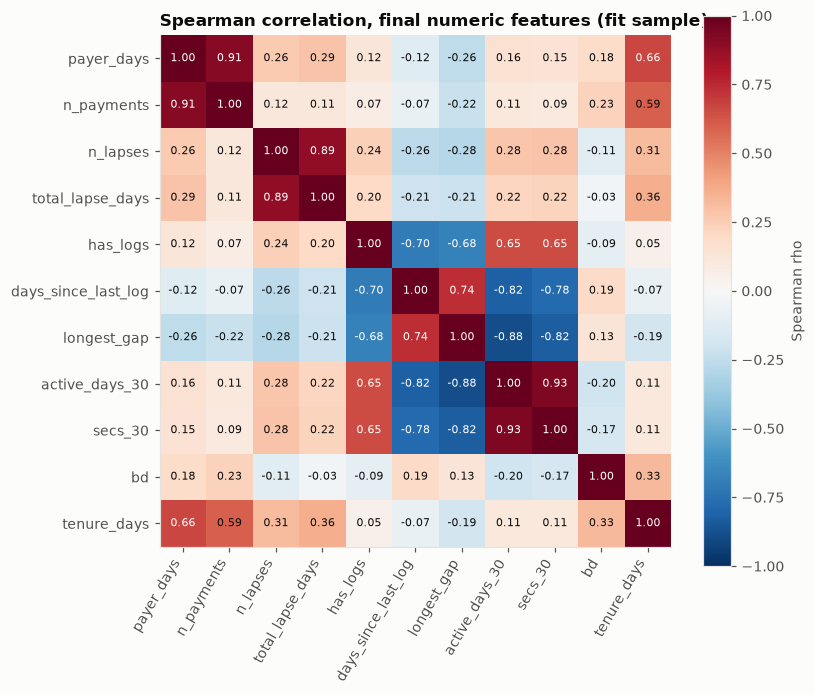

In [7]:
NUM_FINAL = C.HISTORY_BLOCK + C.LISTEN_BLOCK + C.MEMBER_NUM
rho = fit.select(NUM_FINAL).sample(n=200_000, seed=C.SEED).to_pandas().corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(rho.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(NUM_FINAL)):
    for j in range(len(NUM_FINAL)):
        ax.text(j, i, f"{rho.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(rho.iat[i, j]) > 0.6 else C.COLORS["text"])
ax.set_xticks(range(len(NUM_FINAL)), NUM_FINAL, rotation=60, ha="right"); ax.set_yticks(range(len(NUM_FINAL)), NUM_FINAL)
ax.grid(False); fig.colorbar(im, ax=ax, label="Spearman rho")
ax.set_title("Spearman correlation, final numeric features (fit sample)", loc="left")
C.save_fig(fig, "08_final_spearman"); plt.show()


Four pairs remain strongly correlated: `payer_days`–`n_payments` (0.91), `n_lapses`–`total_lapse_days` (0.89), `active_days_30`–`secs_30` (0.93) and `longest_gap`–`active_days_30` (−0.88). Each pair was tested in notebooks 04 and 06 and the second member added a little. Trees are robust to this, and in the linear model they enter as bands. They are kept; if the linear baseline shows unstable coefficients, drop `n_payments` and `secs_30` first.


## 6. Drift between February (fit) and March (test), without labels

The same features are rebuilt for the March cohort (`train_v2`, cutoff 2017-02-28) with the levels learned on fit (payment methods, cities). **No March label is read.** Expiry levels keep their February names, so for March `february` means "expires within 28 days of the cutoff", `march` means 29–59 days, and so on. The Population Stability Index (PSI) compares each feature's distribution: below 0.1 stable, 0.1–0.25 moderate shift, above 0.25 large shift.

In [8]:
C.set_cutoff(MAR_CUTOFF)
march_users = pl.read_parquet(C.PARQUET_DIR / "train_v2.parquet", columns=["msno"]).with_columns(is_churn=pl.lit(None, dtype=pl.Int8))
mar, _ = build_features(march_users, keep_methods=KEEP_METHODS, keep_cities=KEEP_CITIES)
C.set_cutoff(FEB_CUTOFF)
print(f"March customers: {mar.height:,} (labels not loaded)")

def psi(a: np.ndarray, b: np.ndarray, categorical: bool) -> float:
    eps = 1e-6
    if categorical:
        levels = np.union1d(np.unique(a.astype(str)), np.unique(b.astype(str)))
        pa = np.array([(a.astype(str) == l).mean() for l in levels]); pb = np.array([(b.astype(str) == l).mean() for l in levels])
    else:
        a, b = a.astype(float), b.astype(float)
        na_a, na_b = np.isnan(a).mean(), np.isnan(b).mean()
        edges = np.unique(np.nanquantile(a, np.linspace(0, 1, 11)))
        ha = np.histogram(a[~np.isnan(a)], bins=edges)[0] / len(a)
        hb = np.histogram(np.clip(b[~np.isnan(b)], edges[0], edges[-1]), bins=edges)[0] / len(b)
        pa, pb = np.append(ha, na_a), np.append(hb, na_b)
    pa, pb = pa + eps, pb + eps
    return float(np.sum((pb - pa) * np.log(pb / pa)))

ALL_FINAL = FULL + list(OPEN)
rows = []
for c in ALL_FINAL:
    cat = c in CAT_ALL
    rows.append({"feature": c, "type": "cat" if cat else "num",
                 "psi": psi(fit[c].to_numpy(), mar[c].to_numpy(), cat)})
drift = pd.DataFrame(rows).sort_values("psi", ascending=False).reset_index(drop=True)
drift["level"] = pd.cut(drift["psi"], [-1, 0.1, 0.25, 99], labels=["stable", "moderate", "large"])
drift

March customers: 970,960 (labels not loaded)


,feature,type,psi,level
0,payer_days,num,0.8454,large
1,expire_dow,cat,0.1567,moderate
2,expiry_state,cat,0.1164,moderate
3,dsl_band,cat,0.0324,stable
4,price_level,cat,0.0127,stable
5,days_since_last_log,num,0.0094,stable
6,n_payments,num,0.0065,stable
7,tenure_days,num,0.0028,stable
8,pm_group,cat,0.0023,stable
9,secs_30,num,0.0017,stable


In [9]:
top = drift.head(4)["feature"].tolist()
for c in top:
    if c in CAT_ALL:
        a = fit[c].value_counts(normalize=True).rename({"proportion": "fit"})
        b = mar[c].value_counts(normalize=True).rename({"proportion": "march"})
        print(f"\n{c}"); print(a.join(b, on=c, how="full", coalesce=True).sort("fit", descending=True, nulls_last=True).head(10))
    else:
        print(f"\n{c}"); print(pl.DataFrame({"q": [0.1, 0.25, 0.5, 0.75, 0.9],
              "fit": [fit[c].quantile(q) for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
              "march": [mar[c].quantile(q) for q in (0.1, 0.25, 0.5, 0.75, 0.9)]}))


payer_days
shape: (5, 3)
┌──────┬───────┬───────┐
│ q    ┆ fit   ┆ march │
│ ---  ┆ ---   ┆ ---   │
│ f64  ┆ f64   ┆ f64   │
╞══════╪═══════╪═══════╡
│ 0.1  ┆ 112.0 ┆ 109.0 │
│ 0.25 ┆ 285.0 ┆ 285.0 │
│ 0.5  ┆ 508.0 ┆ 527.0 │
│ 0.75 ┆ 731.0 ┆ 759.0 │
│ 0.9  ┆ 751.0 ┆ 779.0 │
└──────┴───────┴───────┘

expire_dow
shape: (8, 3)
┌────────────┬──────────┬──────────┐
│ expire_dow ┆ fit      ┆ march    │
│ ---        ┆ ---      ┆ ---      │
│ str        ┆ f64      ┆ f64      │
╞════════════╪══════════╪══════════╡
│ 2          ┆ 0.223459 ┆ 0.1153   │
│ 1          ┆ 0.131982 ┆ 0.122841 │
│ 6          ┆ 0.129937 ┆ 0.133301 │
│ 4          ┆ 0.129521 ┆ 0.138755 │
│ 3          ┆ 0.128738 ┆ 0.106256 │
│ 7          ┆ 0.127143 ┆ 0.134619 │
│ 5          ┆ 0.127055 ┆ 0.246324 │
│ none       ┆ 0.002165 ┆ 0.002603 │
└────────────┴──────────┴──────────┘

expiry_state
shape: (6, 3)
┌──────────────┬──────────┬──────────┐
│ expiry_state ┆ fit      ┆ march    │
│ ---          ┆ ---      ┆ ---      │
│ str     

### 6.1 Are the two shifts real or artefacts of the definitions?

- `payer_days` is measured from the first transaction, and the log starts on 2015-01-01, so the cap moves with the cutoff (761 days in February, 789 in March). Test: cap it at a fixed 730 days.
- `expiry_state` uses fixed day counts (≤ 28 days = "february"). February has 28 days but March has 31, so March expiries on the 29th–31st fall into the next band only because of the calendar. Test: define the state by **calendar month** of the expiry (label month / next month / later).

In [10]:
def month_expiry(df, cutoff):
    first_label = (pd.Timestamp(cutoff) + pd.Timedelta(days=1)).date()
    nxt = (pd.Timestamp(first_label) + pd.offsets.MonthBegin(1)).date()
    after = (pd.Timestamp(nxt) + pd.offsets.MonthBegin(1)).date()
    e = pl.col("last_expire")
    return df.with_columns(expiry_month=pl.when(pl.col("expiry_state") == "no txn").then(pl.lit("no txn"))
        .when(e.is_null()).then(pl.lit("unknown")).when(e <= pl.lit(cutoff)).then(pl.lit("lapsed"))
        .when(e < pl.lit(nxt)).then(pl.lit("label month")).when(e < pl.lit(after)).then(pl.lit("next month"))
        .otherwise(pl.lit("later")))

fit = month_expiry(fit, FEB_CUTOFF).with_columns(payer_days_cap=pl.col("payer_days").clip(upper_bound=730))
mar = month_expiry(mar, MAR_CUTOFF).with_columns(payer_days_cap=pl.col("payer_days").clip(upper_bound=730))
fix = pd.DataFrame([
    {"feature": "payer_days (raw)", "psi": psi(fit["payer_days"].to_numpy(), mar["payer_days"].to_numpy(), False)},
    {"feature": "payer_days capped at 730", "psi": psi(fit["payer_days_cap"].to_numpy(), mar["payer_days_cap"].to_numpy(), False)},
    {"feature": "expiry_state (day counts)", "psi": psi(fit["expiry_state"].to_numpy(), mar["expiry_state"].to_numpy(), True)},
    {"feature": "expiry_month (calendar months)", "psi": psi(fit["expiry_month"].to_numpy(), mar["expiry_month"].to_numpy(), True)},
])
print(fix.to_string(index=False))
a = fit["expiry_month"].value_counts(normalize=True).rename({"proportion": "fit"})
b = mar["expiry_month"].value_counts(normalize=True).rename({"proportion": "march"})
print(a.join(b, on="expiry_month", how="full", coalesce=True).sort("fit", descending=True, nulls_last=True))
data = fit.to_pandas()
CAT_ALL.add("expiry_month")
FINAL = [c if c != "expiry_state" else "expiry_month" for c in FULL]
FINAL = [c if c != "payer_days" else "payer_days_cap" for c in FINAL]
pd.DataFrame({"full (4 blocks)": abl.loc["full (4 blocks)", ["roc_auc", "avg_precision", "log_loss", "n_features"]].to_dict(),
              "final (month expiry, capped payer_days)": gbm_cv(FINAL)}).T

                       feature    psi
              payer_days (raw) 0.8454
      payer_days capped at 730 0.0039
     expiry_state (day counts) 0.1164
expiry_month (calendar months) 0.0014
shape: (6, 3)
┌──────────────┬──────────┬──────────┐
│ expiry_month ┆ fit      ┆ march    │
│ ---          ┆ ---      ┆ ---      │
│ str          ┆ f64      ┆ f64      │
╞══════════════╪══════════╪══════════╡
│ label month  ┆ 0.88993  ┆ 0.891688 │
│ next month   ┆ 0.086095 ┆ 0.079749 │
│ lapsed       ┆ 0.014188 ┆ 0.017501 │
│ later        ┆ 0.007622 ┆ 0.00846  │
│ no txn       ┆ 0.002157 ┆ 0.002599 │
│ unknown      ┆ 0.000008 ┆ 0.000003 │
└──────────────┴──────────┴──────────┘


,roc_auc,avg_precision,log_loss,n_features
full (4 blocks),0.9001,0.5967,0.1421,20.0000
"final (month expiry, capped payer_days)",0.9001,0.5964,0.1422,20.0000



Without looking at any March label:

- Almost every feature is **stable** between February and March (PSI < 0.04).
- `payer_days` (PSI 0.85) and `expiry_state` (0.12) look shifted, and `expire_dow` (0.16) too. All three are **artefacts of the definitions**, not changes in the customers (section 6.1):
  - `payer_days` hits the 2015-01-01 start of the log, and that cap moves with the cutoff.
  - `expiry_state` uses fixed day counts, and February has 28 days while March has 31.
  - `expire_dow` depends on which weekdays a given month contains (and is dropped anyway).


## 7. Final feature set


| # | Feature | Block | Type | Definition (as of the cutoff) | Notebook |
|---|---|---|---|---|---|
| 1 | `state` | state | cat | last transaction **day**: auto-renew / manual / cancel / cancel + payment / no txn | 02, 03 |
| 2 | `expiry_month` | state | cat | latest valid expiry of that day by calendar month: lapsed / label month / next month / later / unknown / no txn | 00, 03, 08 |
| 3 | `plan_band` | state | cat | plan days of the last payment: ≤ 7 / 30–31 / 32–200 / 201+ / unknown | 03 |
| 4 | `price_level` | state | cat | list price of the last payment: 99 / 100 / 129 / 149 / 150 / 180 / other | 03 |
| 5 | `price_type` | state | cat | last payment full / discounted / free / none (2015 missing plan fields → unknown) | 02, 03 |
| 6 | `pm_group` | state | cat | last payment method, methods with < 1,000 fit customers → other | 03 |
| 7 | `payer_days` | history | num | days since the first transaction, **capped at 730** | 04, 08 |
| 8 | `n_payments` | history | num | payment records (cancellations excluded) | 04 |
| 9 | `n_lapses` | history | num | payment days after the previous expiry | 04 |
| 10 | `total_lapse_days` | history | num | total days between an expiry and the next payment | 04 |
| 11 | `has_logs` | listening | flag | any listening day in the 90-day window | 00, 06 |
| 12 | `days_since_last_log` | listening | num | days from the last listening day to the cutoff (90 if none) | 06 |
| 13 | `longest_gap` | listening | num | longest run of silent days in the window, tail included | 06 |
| 14 | `active_days_30` | listening | num | listening days in the last 30 days | 06 |
| 15 | `secs_30` | listening | num | seconds in the last 30 days (days > 24 h rescaled) | 05, 06 |
| 16 | `via` | members | cat | `registered_via`, `no member` level | 01 |
| 17 | `profile_state` | members | cat | complete / incomplete (no valid age and no gender) / no member | 01 |
| 18 | `age_band` | members | cat | ≤ 18 / 19–21 / 22–24 / 25–29 / 30–44 / 45+ / unknown / no member | 01 |
| 19 | `bd` | members | num | age 1–100, otherwise NaN (no imputation) | 01 |
| 20 | `tenure_days` | members | num | days since registration, NaN if missing or after the cutoff | 01 |

**Linear model only:** numeric features as bands, plus `state × expiry_month`, `via × profile_state` and the history and recency bands crossed with "manual payment".

**w2:** the daily channels keep the notebook-05 cleaning (24 h rescale, `log1p`, no quantile clipping) and the notebook-02/03 day-level transaction state. Features 1–10 and 16–20 enter as a **static branch** (notebook 07).


## 8. Conclusions


- **20 features, all justified by the data**, replace the 108 columns of the current w1 export and do better with the same model (AUC 0.900 vs 0.898, AP 0.597 vs 0.588, log-loss 0.142 vs 0.144). The order of importance is clear: subscription state ≫ listening > history > members.
- The gain is not in a new trick. It comes from **cleaning the data correctly** (as-of filter, 2015 zeros, day-level state, impossible listening days) and **dropping what does not work** (mean-imputed age, cumulative duration, file-order flags, active-month blocks, quantile clipping).
- The set is **stable between February and March**, once two definitions are fixed so that they do not depend on the calendar: `payer_days` capped at 730 days, and the expiry state by calendar month.
- What the EDA cannot settle, and is left to w1/w2 modelling: 60 vs 90-day sequences (notebook 07), and whether the linear baseline needs the redundant pairs.


In [11]:
decisions = C.write_decisions("08", "Integration, redundancy and drift", [
    {"finding": "Ablation: state -0.20 AP, listening -0.024, history -0.012, members -0.0014 when removed",
     "decision": "Final set = 4 blocks, 20 features (table in section 7)",
     "kind": "new feature"},
    {"finding": "dsl_band, expire_dow, city_group, n_free, n_methods, auto_share each move AUC/AP by <= 0.0005",
     "decision": "Drop all open candidates (closes the open items of notebooks 03 and 04)",
     "kind": "drop"},
    {"finding": "Logistic regression: interactions add +0.012 AP (0.556 -> 0.568); GBM 0.597",
     "decision": "w1 linear baseline uses bands + state x expiry, via x profile, history/recency x manual; GBM is the reference model",
     "kind": "transformation"},
    {"finding": "20 proposed features beat the 108 current w1 columns with the same GBM (AUC 0.9001 vs 0.8976, AP 0.597 vs 0.588)",
     "decision": "Rewrite w1/src/data_processing to produce the 20-feature table",
     "kind": "transformation"},
    {"finding": "payer_days PSI 0.85 Feb -> Mar because the 2015-01-01 log start caps it at a cutoff-dependent value",
     "decision": "Cap `payer_days` at 730 days (PSI 0.004, no performance loss)",
     "kind": "transformation"},
    {"finding": "expiry_state PSI 0.12 because fixed day counts meet months of 28 vs 31 days",
     "decision": "Replace by `expiry_month` (lapsed / label month / next month / later); PSI 0.001, no performance loss",
     "kind": "transformation"},
    {"finding": "All other features stable (PSI < 0.04) without using March labels",
     "decision": "No drift handling needed beyond the two fixes; keep a PSI check in the pipeline",
     "kind": "no action"},
    {"finding": "Correlated pairs remain (payer_days-n_payments 0.91, active_days_30-secs_30 0.93, ...)",
     "decision": "Keep for trees; if the linear baseline is unstable drop n_payments and secs_30 first",
     "kind": "open"},
])
decisions

,finding,decision,kind
0,"Ablation: state -0.20 AP, listening -0.024, history -0.012, members -0.0014 when removed","Final set = 4 blocks, 20 features (table in section 7)",new feature
1,"dsl_band, expire_dow, city_group, n_free, n_methods, auto_share each move AUC/AP by <= 0.0005",Drop all open candidates (closes the open items of notebooks 03 and 04),drop
2,Logistic regression: interactions add +0.012 AP (0.556 -> 0.568); GBM 0.597,"w1 linear baseline uses bands + state x expiry, via x profile, history/recency x manual; GBM is the reference model",transformation
3,"20 proposed features beat the 108 current w1 columns with the same GBM (AUC 0.9001 vs 0.8976, AP 0.597 vs 0.588)",Rewrite w1/src/data_processing to produce the 20-feature table,transformation
4,payer_days PSI 0.85 Feb -> Mar because the 2015-01-01 log start caps it at a cutoff-dependent value,"Cap `payer_days` at 730 days (PSI 0.004, no performance loss)",transformation
5,expiry_state PSI 0.12 because fixed day counts meet months of 28 vs 31 days,"Replace by `expiry_month` (lapsed / label month / next month / later); PSI 0.001, no performance loss",transformation
6,All other features stable (PSI < 0.04) without using March labels,No drift handling needed beyond the two fixes; keep a PSI check in the pipeline,no action
7,"Correlated pairs remain (payer_days-n_payments 0.91, active_days_30-secs_30 0.93, ...)",Keep for trees; if the linear baseline is unstable drop n_payments and secs_30 first,open


---
**Previous:** `07_trajectories.ipynb` · End of the EDA series. The decisions in `DECISIONS.md` are the specification for `w1/src/data_processing` and `w2/src/data_processing`.